# Week 4 Capstone — Predicting Internship Selection Outcomes

**Name:** Shiza Ali

**Program:** Data Science Internship

**Organization:** NextGen Learners

## Project Objective

The objective of this project is to build a Machine Learning model
to predict internship selection outcomes using applicant data.

## Importing all the required libraries:

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
#loading the dataset
df = pd.read_csv("applicants_cleaned.csv")

In [4]:
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (73, 7)


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ali Farooq,ali.farooq1@example.com,364944897,Mobile App Development,Government College University Faisalabad,2026-08-08,Selected
1,Saad Farooq,saad.farooq2@example.com,378075619,Web Development,COMSATS University,2026-08-28,Under Review
2,Noor Ali,noor.ali3@example.com,348405908,Graphic Design,The University of Faisalabad,2026-11-09,Under Review
3,LAIBA SIDDIQUI,laiba.siddiqui4@example.com,326682487,Digital Marketing,The University of Faisalabad,2026-10-12,Under Review
4,Iqra Farooq,iqra.farooq5@example.com,372754275,Graphic Design,COMSATS University,2026-08-12,Under Review


In [8]:
#Check dataset columns and missing values
print("Column Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nApplication Status:")
print(df["Status"].value_counts())

Column Names:
['Applicant Name', 'Email', 'Phone', 'Domain Applied', 'University', 'Application Date', 'Status']

Missing Values:
Applicant Name      0
Email               0
Phone               0
Domain Applied      0
University          0
Application Date    0
Status              0
dtype: int64

Application Status:
Status
Under Review    34
Selected        23
Rejected        16
Name: count, dtype: int64


## Adding 4 new features to the dataset:

In [12]:
# Setting seed for reproducible results
np.random.seed(42)

In [16]:
# FIRST simulated feature : num_skills_listed
df['num_skills_listed'] = np.random.randint(1, 9, size=len(df))

In [17]:
# SECOND simulated feature : has_portfolio
df['has_portfolio'] = np.random.choice(
    ['Yes', 'No'],
    size=len(df),
    p=[0.4, 0.6]
)

In [18]:
# THIRD simulated feature : prior_hackathon_participation
df['prior_hackathon_participation'] = np.random.choice(
    ['Yes', 'No'],
    size=len(df),
    p=[0.3, 0.7]
)

In [19]:
# FOURTH simulated feature : statement_quality_score
df['statement_quality_score'] = np.random.randint(
    1, 11, size=len(df)
)

In [20]:
print("New features added successfully!")
df.head()

New features added successfully!


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
0,Ali Farooq,ali.farooq1@example.com,364944897,Mobile App Development,Government College University Faisalabad,2026-08-08,Selected,7,No,No,3
1,Saad Farooq,saad.farooq2@example.com,378075619,Web Development,COMSATS University,2026-08-28,Under Review,6,No,No,1
2,Noor Ali,noor.ali3@example.com,348405908,Graphic Design,The University of Faisalabad,2026-11-09,Under Review,2,No,Yes,1
3,LAIBA SIDDIQUI,laiba.siddiqui4@example.com,326682487,Digital Marketing,The University of Faisalabad,2026-10-12,Under Review,3,Yes,No,8
4,Iqra Farooq,iqra.farooq5@example.com,372754275,Graphic Design,COMSATS University,2026-08-12,Under Review,7,Yes,No,10


In [21]:
new_features = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
]
df[new_features].describe(include='all')

,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score
count,73.000000,73,73,73.000000
unique,NaN,2,2,NaN
top,NaN,No,No,NaN
freq,NaN,47,51,NaN
mean,4.643836,NaN,NaN,5.383562
std,2.546075,NaN,NaN,3.039692
min,1.000000,NaN,NaN,1.000000
25%,3.000000,NaN,NaN,3.000000
50%,4.000000,NaN,NaN,5.000000
75%,7.000000,NaN,NaN,8.000000


## Simulated Features

Four additional features were generated using NumPy:
- Number of skills listed
- Portfolio availability
- Previous hackathon participation
- Statement quality score

These features are simulated for educational purposes and do not
represent actual historical applicant information.

A random seed of 42 was used to ensure reproducibility.
In a real-world system, these features should be collected
directly from applicants.

In [22]:
df.to_csv("applicants_feature_engineered.csv", index=False)

## Feature Preparation — Getting Data Ready for a Model:

**Convert Yes/No columns (has_portfolio & prior_hackathon_participation) to 0/1**


In [24]:
df['has_portfolio'] = df['has_portfolio'].map({
    'Yes': 1,
    'No': 0
})

In [25]:
df['prior_hackathon_participation'] = df[
    'prior_hackathon_participation'
].map({
    'Yes': 1,
    'No': 0
})

In [26]:
df[['has_portfolio', 'prior_hackathon_participation']].head()

,has_portfolio,prior_hackathon_participation
0,0,0
1,0,0
2,0,1
3,1,0
4,1,0


**Convert your target column (what you're predicting) to 0/1 --> status column**


In [27]:
df['target'] = df['Status'].apply(
    lambda x: 1 if x == 'Selected' else 0
)

df[['Status', 'target']].head(10)

,Status,target
0,Selected,1
1,Under Review,0
2,Under Review,0
3,Under Review,0
4,Under Review,0
5,Under Review,0
6,Selected,1
7,Rejected,0
8,Under Review,0
9,Selected,1


In [28]:
#Removing Under Review rows
df_model = df[df['Status'] != 'Under Review'].copy()

print("Original Dataset:", df.shape)
print("Dataset after removing Under Review:", df_model.shape)

Original Dataset: (73, 12)
Dataset after removing Under Review: (39, 12)


In [29]:
print("\nStatus Counts:")
print(df_model['Status'].value_counts())


Status Counts:
Status
Selected    23
Rejected    16
Name: count, dtype: int64


In [30]:
#One-hot encode the Domain column
df_model = pd.get_dummies(
    df_model,
    columns=['Domain Applied'],
    drop_first=True,
    dtype=int
)

df_model.head()

,Applicant Name,Email,Phone,University,Application Date,Status,num_skills_listed,has_portfolio,prior_hackathon_participation,statement_quality_score,target,Domain Applied_Digital Marketing,Domain Applied_Graphic Design,Domain Applied_Mobile App Development,Domain Applied_Web Development
0,Ali Farooq,ali.farooq1@example.com,364944897,Government College University Faisalabad,2026-08-08,Selected,7,0,0,3,1,0,0,1,0
6,Hira Malik,hira.malik7@example.com,365283971,University of Sargodha,2026-09-02,Selected,8,1,0,3,1,0,0,0,0
7,Abdullah Chaudhry,abdullah.chaudhry8@example.com,303817910,Punjab University,2026-08-30,Rejected,2,0,1,2,0,0,0,1,0
9,Hira Chaudhry,hira.chaudhry10@example.com,328026000,The University of Faisalabad,2026-09-29,Selected,1,0,0,7,1,0,1,0,0
10,Hamza Ali,hamza.ali11@example.com,365238695,National University of Sciences and Technology,2026-09-17,Selected,4,0,0,1,1,0,1,0,0


In [31]:
print("New Dataset Shape:", df_model.shape)
print("\nNew Columns:")
print(df_model.columns.tolist())

New Dataset Shape: (39, 15)

New Columns:
['Applicant Name', 'Email', 'Phone', 'University', 'Application Date', 'Status', 'num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'target', 'Domain Applied_Digital Marketing', 'Domain Applied_Graphic Design', 'Domain Applied_Mobile App Development', 'Domain Applied_Web Development']


In [32]:
#Select your final feature set
feature_columns = [
    'num_skills_listed',
    'has_portfolio',
    'prior_hackathon_participation',
    'statement_quality_score'
] + [
    col for col in df_model.columns
    if col.startswith('Domain Applied_')
]

X = df_model[feature_columns]
y = df_model['target']

In [33]:
print("Feature Columns:")
print(feature_columns)

Feature Columns:
['num_skills_listed', 'has_portfolio', 'prior_hackathon_participation', 'statement_quality_score', 'Domain Applied_Digital Marketing', 'Domain Applied_Graphic Design', 'Domain Applied_Mobile App Development', 'Domain Applied_Web Development']


In [34]:
print("\nX Shape:", X.shape)
print("y Shape:", y.shape)


X Shape: (39, 8)
y Shape: (39,)


## Feature Preparation

In this step, the dataset was prepared for machine learning.

The following preprocessing operations were performed:

1. Converted categorical Yes/No values into numerical values (1/0).
2. Created a target variable where Selected = 1 and Rejected = 0.
3. Removed applicants with Under Review status because their final outcomes were not confirmed.
4. Applied One-Hot Encoding to the Domain Applied column using `pd.get_dummies()` with `drop_first=True`.
5. Selected eight relevant features for model training.

**Final Dataset:**
- Total confirmed applicants: 39
- Selected applicants: 23
- Rejected applicants: 16
- Input features: 8
- Target variable: `target`

**Note:** Four additional applicant features were simulated using NumPy for educational purposes. They do not represent actual applicant information.

## TRAIN/TEST Split

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [36]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

Training Features: (31, 8)
Testing Features: (8, 8)


In [37]:
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Target: (31,)
Testing Target: (8,)


###  Splitting the Dataset into Training and Testing Sets

Before training the machine learning model, the dataset was divided into two subsets: training data and testing data.

The `train_test_split()` function from Scikit-learn was used to perform this operation.

**Splitting Configuration:**
- Training Size: 80%
- Testing Size: 20%
- Random State: 42
- Stratification: Applied using the target variable.

**Purpose of Data Splitting:**

- Training data is used to teach the model and help it learn patterns from the input features.
- Testing data is used to evaluate the model's performance on records it has not seen during training.
- `random_state=42` ensures reproducibility, meaning the same split can be obtained when the code is executed again.
- `stratify=y` maintains approximately the same proportion of Selected and Rejected applicants in both subsets.

**Dataset Splitting Results:**

| Subset | Records | Features |
|---|---:|---:|
| Training Set | 31 | 8 |
| Testing Set | 8 | 8 |
| Total | 39 | 8 |

**Observation:**

The dataset was successfully divided into 31 training records and 8 testing records. Due to the small number of confirmed applicant records, the testing results should be interpreted carefully.

## Train the Model --> Using Logistic Regression

In [38]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Training the Machine Learning Model

After splitting the dataset, Logistic Regression was selected as the classification algorithm to predict internship selection outcomes.

**Why Logistic Regression?**

- It is a supervised machine learning algorithm.
- It is commonly used for binary classification problems.
- It predicts the probability of an outcome belonging to a particular class.
- It is relatively simple to understand and interpret.
- It provides coefficients that can help explain how input features are associated with the predicted outcome.

**Model Configuration:**

The Logistic Regression model was initialized using:

`LogisticRegression(max_iter=1000)`

- `LogisticRegression()` creates the classification model.
- `max_iter=1000` allows the optimization algorithm up to 1,000 iterations to find suitable model parameters.
- `model.fit(X_train, y_train)` trains the model using the training features and their corresponding target labels.

**Training Process:**

The model was trained using eight selected input features:

1. Number of skills listed
2. Portfolio availability
3. Previous hackathon participation
4. Statement quality score
5. Domain Applied — Digital Marketing
6. Domain Applied — Graphic Design
7. Domain Applied — Mobile App Development
8. Domain Applied — Web Development

The target variable represents internship selection outcomes:
- 1 = Selected
- 0 = Rejected

**Training Result:**

The Logistic Regression model was successfully trained using 31 applicant records.

**Important Note:**

Four applicant-related features were simulated using NumPy for educational purposes. Therefore, the model's learned patterns do not represent verified real-world selection criteria. The model is intended for educational analysis and decision-support demonstration, not actual recruitment decisions.

In [39]:
# Making predictions on the test set:
y_pred = model.predict(X_test)

In [40]:
print("Actual Results:")
print(y_test.values)

Actual Results:
[0 0 1 1 1 1 0 1]


In [41]:
print("\nPredicted Results:")
print(y_pred)


Predicted Results:
[1 1 1 1 1 1 0 0]


In [42]:
# Comparin Actual vs Predicted results
results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})
results

,Actual,Predicted
0,0,1
1,0,1
2,1,1
3,1,1
4,1,1
5,1,1
6,0,0
7,1,0


###  Generating Predictions:

After training the Logistic Regression model, predictions were generated using the testing dataset.

The `predict()` method was applied to `X_test` to predict the selection outcomes of applicants who were not included in the training process.

**Prediction Labels:**
- 1 = Selected
- 0 = Rejected

The predicted outcomes (`y_pred`) were compared with the actual outcomes (`y_test`) to examine the model's initial prediction performance.

**Observation:**

The model correctly predicted 5 out of 8 testing records, while 3 predictions were incorrect.

These initial results provide an overview of the model's predictions. Further evaluation using accuracy, precision, recall, and a confusion matrix is required to understand its performance in more detail.

## Evaluate the Model — Honestly

**Accuracy:**

In [44]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2%}")

Accuracy: 62.50%


**Precision:**

In [45]:
precision = precision_score(
    y_test, y_pred, zero_division=0
)
print(f"Precision: {precision:.2%}")

Precision: 66.67%


**Recall:**

In [47]:
recall = recall_score(
    y_test, y_pred, zero_division=0
)
print(f"Recall: {recall:.2%}")

Recall: 80.00%


### Understanding Model Evaluation Metrics

The Logistic Regression model was evaluated using three important performance metrics: Accuracy, Precision, and Recall.

**1. Accuracy: 62.50%**

Accuracy answers the question:

"Out of all the applicants, what percentage did my model predict correctly?"

Our model correctly predicted 5 out of 8 applicants.

- Correct predictions: 5
- Total predictions: 8
- Accuracy: 62.50%

This means that the model made correct predictions for 62.50% of the testing applicants.

**2. Precision: 66.67%**

Precision answers the question:

"Of all the applicants my model predicted would be Selected, what percentage were actually Selected?"

Our model predicted 6 applicants as Selected, and 4 of them were actually Selected.

- True Positives: 4
- False Positives: 2
- Precision: 66.67%

This means that approximately 66.67% of the applicants predicted as Selected were actually Selected. Higher precision means fewer false promises.

**3. Recall: 80.00%**

Recall answers the question:

"Of all the applicants who were actually Selected, what percentage did my model correctly catch?"

There were 5 actually Selected applicants, and the model correctly identified 4 of them.

- True Positives: 4
- False Negatives: 1
- Recall: 80.00%

This means that the model successfully identified 80% of the actually Selected applicants. Higher recall means fewer missed strong candidates.

**Overall Interpretation:**

The model achieved 62.50% accuracy, 66.67% precision, and 80.00% recall.

Its recall was higher than its precision, indicating that it identified most selected applicants but also incorrectly classified some rejected applicants as selected.

**Limitation:** These results are based on only 8 testing records from a dataset of 39 confirmed applicants. Additionally, four features were simulated for educational purposes. Therefore, these metrics should not be considered evidence of reliable real-world recruitment performance.

**Confusion Matrix**

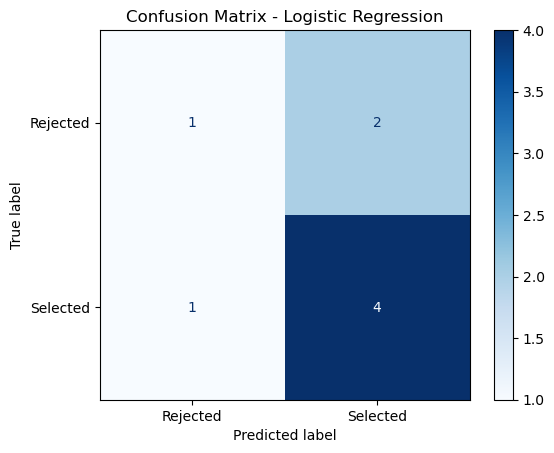

In [48]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Rejected', 'Selected']
)

disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

### Confusion Matrix Interpretation

The confusion matrix was used to compare the actual and predicted internship selection outcomes.

The results were:

- True Negative (TN): 1
- False Positive (FP): 2
- False Negative (FN): 1
- True Positive (TP): 4

**Observations:**

1. The model correctly identified 4 selected applicants.
2. It correctly identified 1 rejected applicant.
3. It incorrectly classified 2 rejected applicants as selected.
4. It incorrectly classified 1 selected applicant as rejected.

The model achieved 5 correct predictions out of 8 testing records.

**Overall Finding:**

The model performed better at identifying selected applicants than rejected applicants in this small test sample. However, it also produced false positive predictions, which means some rejected applicants were incorrectly classified as selected.

##  Model Limitations and Ethical Considerations

Although the Logistic Regression model produced predictions and measurable results, several limitations must be considered before interpreting its performance.

### 1. Small and Partly Simulated Dataset

The original dataset contained 73 applicants. However, after removing 34 applicants with an Under Review status, only 39 confirmed applicant records remained for model training and testing.

Additionally, four features were artificially generated using NumPy:
- Number of skills listed
- Portfolio availability
- Previous hackathon participation
- Statement quality score

These simulated features do not represent actual historical applicant information or real applicant behaviour. Therefore, the model cannot learn genuine relationships between these characteristics and internship selection outcomes.

### 2. Small Testing Dataset and Unstable Results

The dataset was divided into 80% training data and 20% testing data.

As a result:
- Training records: 31
- Testing records: 8

Since the testing dataset contains only 8 applicants, even one incorrect prediction can noticeably change the evaluation metrics.

If the dataset is split differently, the model's accuracy, precision, and recall may change significantly.

Therefore, the reported results are illustrative of the machine learning process and should not be considered a production-ready performance guarantee.

### 3. Potential Bias in Selection Decisions

Machine learning models can learn and repeat biases present in historical selection decisions.

For example, if applicants from certain universities were historically preferred for reasons unrelated to their skills or qualifications, a model trained on those decisions could learn and reproduce that unfair preference.

This could lead to unfair treatment of applicants from other universities or backgrounds.

Although university information was excluded from our selected model features, historical selection bias may still exist in the target labels and other features.

Fairness, transparency, and regular bias testing are essential before using any predictive hiring or selection system.

### 4. Decision-Support Tool, Not a Replacement for Human Review

This model should only be considered an educational decision-support tool.

It should not make final internship selection or rejection decisions independently.

Human reviewers should consider applicants' actual skills, qualifications, experience, portfolios, and individual circumstances before making recruitment decisions.

Final decisions must remain under human supervision to ensure fairness and accountability.

### Overall Conclusion

This project demonstrates how machine learning can be applied to predict internship selection outcomes. However, the small dataset, simulated features, limited testing records, and potential historical biases restrict the reliability of its predictions.

A larger dataset containing genuine applicant information, verified selection outcomes, and carefully reviewed features would be required to develop a more reliable and fair predictive system.

Understanding and communicating these limitations is an important part of responsible and trustworthy data science.

## Interpret — Which Features Mattered Most?

**Using Logistic Regression**

In [49]:
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient',
    ascending=False
)

print(coefficients.to_string(index=False))

                              Feature  Coefficient
        Domain Applied_Graphic Design     0.445556
                        has_portfolio     0.359891
        prior_hackathon_participation     0.236875
     Domain Applied_Digital Marketing     0.235534
              statement_quality_score     0.130573
Domain Applied_Mobile App Development    -0.377237
                    num_skills_listed    -0.378947
       Domain Applied_Web Development    -0.412302


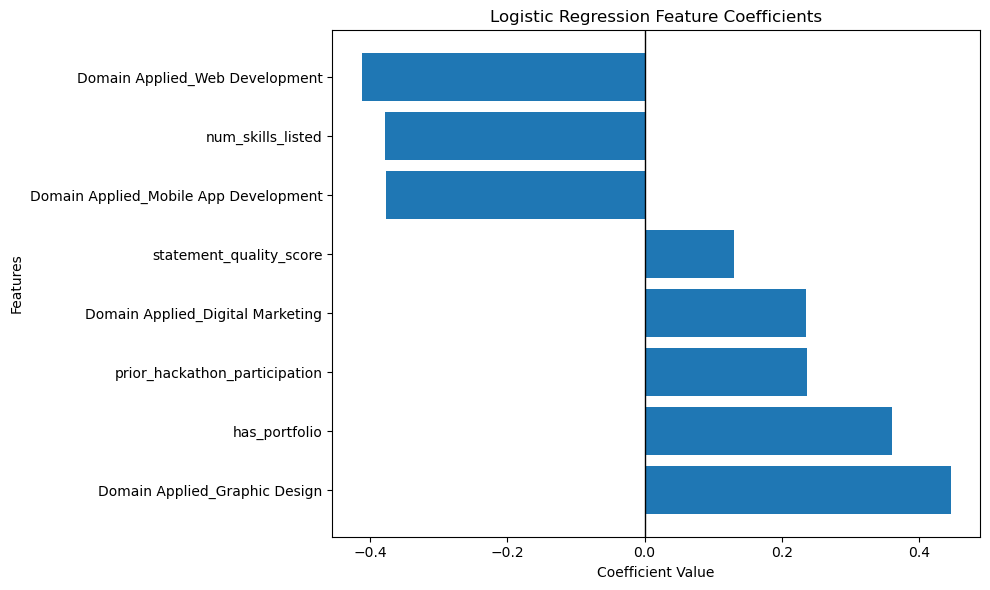

In [50]:
# Visualization
plt.figure(figsize=(10, 6))
plt.barh(
    coefficients['Feature'],
    coefficients['Coefficient']
)
plt.axvline(x=0, color='black', linewidth=1)
plt.xlabel('Coefficient Value')
plt.ylabel('Features')
plt.title('Logistic Regression Feature Coefficients')
plt.tight_layout()
plt.show()

### Interpretation of Logistic Regression Coefficients

Logistic Regression coefficients help us understand which features were positively or negatively associated with the model's prediction of internship selection.

**Key Findings:**

- `Domain Applied_Graphic Design` showed the strongest positive coefficient, followed by `has_portfolio`.
- `prior_hackathon_participation` and `Domain Applied_Digital Marketing` also showed positive associations with selection predictions.
- `statement_quality_score` showed a relatively smaller positive association.
- `Domain Applied_Web Development` showed the strongest negative coefficient, while `num_skills_listed` and `Domain Applied_Mobile App Development` also showed negative associations.

**Overall Interpretation:**

In this dataset, the model learned stronger positive associations for Graphic Design domain and portfolio availability, while Web Development and the number of listed skills showed negative associations with predicted selection outcomes.

However, these findings should not be interpreted as actual selection criteria used by NextGen Learners. Four features were simulated, and the dataset was small. The coefficient patterns may change with different or larger datasets. These observations would need to be validated using genuine historical applicant data before drawing real-world conclusions.

**Note:** Coefficients indicate associations, not causation. Their magnitudes are also affected by feature scales.

## Executive Summary

### What We Did

We developed a simple prediction model using NextGenLearners applicant data to explore factors associated with internship selection outcomes. The project involved preparing applicant records, examining selection patterns, and building a model to predict whether an applicant would be Selected or Rejected.

### What We Found

The model correctly predicted 5 out of 8 applicants in the testing group, achieving an accuracy of **62.50%**.

The model showed the strongest positive association with the Graphic Design domain, followed by portfolio availability. Previous hackathon participation and the Digital Marketing domain also showed positive associations with selection predictions.

However, these patterns describe what the model learned from this particular dataset and do not establish the actual reasons behind NextGenLearners' selection decisions.

### Important Caveats

This analysis was based on a small dataset of only 39 applicants with confirmed selection outcomes. Additionally, four applicant-related features, including skill count, portfolio availability, previous hackathon participation, and statement quality, were artificially generated for this exercise rather than collected from actual historical applications.

Because of the small dataset and simulated information, the results are illustrative and should not be treated as a reliable guarantee of future selection outcomes.

Before using such a system in real recruitment, NextGenLearners would need to collect genuine applicant information consistently and validate the model using a much larger dataset. The system could also reflect or repeat unfair patterns present in previous selection decisions.

Therefore, this model should only support human reviewers and must never replace human judgment in final recruitment decisions.

### Recommendation

Consider collecting genuine portfolio or GitHub links and written statements consistently through the internship application form. These details could help future analysis explore whether applicants' practical work and communication skills are associated with selection outcomes. Any future predictive system should be tested on real historical data and regularly reviewed for fairness before being considered for recruitment support.